# EDA y recuperación de pares español–quechua para grabación

**Objetivo:** recuperar pares existentes cuyo español se parezca a las flashcards y producir una
cola de revisión para grabar quechua Chanka. No se generan traducciones ni se reasigna el quechua
de una oración parecida a una flashcard distinta.

Hay dos tareas diferentes: **recuperación exacta** de una flashcard en los corpus y **selección
de nuevas frases similares**, conservando siempre el español original del corpus y su pareja.
La similitud que calculamos es léxica, no equivalencia semántica ni confianza de traducción.

Los Excel incluyen columnas `TEXTO_SHI` / `SHIWILU`: se usan **solo como referencia del español**.
Sus traducciones y sus marcas de audio no son datos de quechua ni grabaciones de este proyecto.
La etiqueta `.quy` es procedencia declarada; la variedad Chanka y la naturalidad deben validarse
con hablantes. Una igualdad de líneas permite emparejar posiciones, pero no demuestra alineamiento.

Ejecuta las celdas en orden. Las fuentes se leen sin modificarlas. Los resultados se guardan
en `resultados_eda/`; cada ejecución crea una carpeta de revisión nueva para conservar anotaciones.


In [5]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib, json, re, unicodedata, sys, platform
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

DATA_DIR = Path.cwd()  # cambiar si el kernel inicia en otro directorio
OUT = DATA_DIR / 'resultados_eda'
OUT.mkdir(exist_ok=True)
RUN = OUT / ('revision_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
RUN.mkdir()
SEED = 42
MIN_PALABRAS, MAX_PALABRAS = 3, 12
MAX_PALABRAS_QUY = 25
N_PILOTO = 300
TOP_K = 3
SIM_MIN = 0.20  # umbral exploratorio, no calibrado con juicios humanos
CUOTAS = {'minedu': 120, 'dict_misc': 90, 'jw300': 90}
ARCHIVOS = {'dict_misc': 'dict_misc.quy-es', 'jw300': 'jw300.es-quy', 'minedu': 'minedu.quy-es'}
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 12)

def normalizar(texto):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(texto))).strip().casefold()

def tokens(texto):
    # Conserva tildes, ñ y apóstrofos internos; no impone normalización dialectal.
    return re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)*|\d+", normalizar(texto))

def clave(texto):
    # Coincidencia NORMALIZADA: ignora puntuación y caja, conserva diacríticos y números.
    return ' '.join(tokens(texto))

def guardar_csv(df, nombre):
    df.to_csv(OUT / nombre, index=False, encoding='utf-8-sig')

def mostrar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(OUT / nombre, dpi=140, bbox_inches='tight')
    display(Image(filename=str(OUT / nombre)))
    plt.close(fig)

print('Datos:', DATA_DIR)
print('Revisión de esta ejecución:', RUN.name)


Datos: /Users/gmeza/Projects/nlp_pipeline/eda
Revisión de esta ejecución: revision_20261006T052518_668885Z


## 1. Inventario reproducible y lectura sin perder el alineamiento

UTF-8 estricto: si hay un error de decodificación se detiene la lectura; no se reemplazan caracteres
silenciosamente. No se borran líneas vacías antes de emparejar. Si los tamaños difieren, se detiene
la carga: un `zip` truncado ocultaría el problema. `linea` es la línea física, empezando en 1.
Se guardan hashes SHA-256 para identificar exactamente la versión de cada entrada.


In [8]:
entradas = [DATA_DIR / f'{base}.{lang}' for base in ARCHIVOS.values() for lang in ['es', 'quy']]
entradas += [DATA_DIR / 'flashcards.xlsx', DATA_DIR / 'flashcards2.xlsx']
inventario = pd.DataFrame([{'archivo': p.name, 'bytes': p.stat().st_size,
    'sha256': hashlib.sha256(p.read_bytes()).hexdigest()} for p in entradas])
display(inventario)
guardar_csv(inventario, 'inventario.csv')

partes, conteos = [], []
for fuente, base in ARCHIVOS.items():
    es = (DATA_DIR / f'{base}.es').read_text(encoding='utf-8-sig').splitlines()
    quy = (DATA_DIR / f'{base}.quy').read_text(encoding='utf-8-sig').splitlines()
    assert len(es) == len(quy), f'Desalineación de tamaños en {fuente}: {len(es)} / {len(quy)}'
    conteos.append({'fuente': fuente, 'lineas_es': len(es), 'lineas_quy': len(quy)})
    partes.append(pd.DataFrame({'fuente': fuente, 'linea': np.arange(1, len(es)+1),
        'archivo_es': f'{base}.es', 'archivo_quy': f'{base}.quy', 'es_original': es, 'quy_original': quy}))
pares = pd.concat(partes, ignore_index=True)
pares['par_id'] = pares.fuente + ':' + pares.linea.astype(str).str.zfill(7)
pares['es_clave'] = pares.es_original.map(clave)
pares['quy_clave'] = pares.quy_original.map(clave)
display(pd.DataFrame(conteos))
print(f'Total: {len(pares):,} pares posicionales')


FileNotFoundError: [Errno 2] No such file or directory: '/Users/gmeza/Projects/nlp_pipeline/eda/dict_misc.quy-es.es'

## 2. Qué español representan las flashcards

`flashcards.xlsx / Sheet1` es la referencia principal de prosa. `flashcards2.xlsx / Sheet1` es
una referencia adicional más breve; se comparan por separado para que su mayor tamaño no redefina
el estilo principal. En `flashcards.xlsx / es` la primera fila es texto, no una cabecera.
También se recupera la primera columna de `Sheet2`, sin convertir sus notas ni el shiwilu en español.
Se preservan archivo, hoja, fila Excel y código. Las repeticiones se conservan en la tabla de
referencias, pero se deduplican al construir el índice de búsqueda.


In [9]:
especificaciones = [
    ('flashcards.xlsx', 'Sheet1', 'TEXTO_SPA', 'principal'),
    ('flashcards2.xlsx', 'Sheet1', 'ESP', 'adicional'),
    ('flashcards.xlsx', 'es', None, 'auxiliar_es'),
    ('flashcards.xlsx', 'Sheet2', None, 'auxiliar_saludos')]
refs, hojas = [], []
for archivo in ['flashcards.xlsx', 'flashcards2.xlsx']:
    libro = pd.ExcelFile(DATA_DIR / archivo)
    for hoja in libro.sheet_names:
        bruto = pd.read_excel(libro, sheet_name=hoja, header=None)
        hojas.append({'archivo': archivo, 'hoja': hoja, 'filas_fisicas_leidas': len(bruto), 'columnas': bruto.shape[1]})
for archivo, hoja, columna, grupo in especificaciones:
    df = pd.read_excel(DATA_DIR / archivo, sheet_name=hoja, header=0 if columna else None)
    serie = df[columna] if columna else df.iloc[:, 0]
    for i, valor in serie.items():
        if pd.isna(valor) or not str(valor).strip():
            continue
        fila = int(i) + (2 if columna else 1)
        refs.append({'ref_id': f'{archivo}:{hoja}:{fila}', 'archivo': archivo, 'hoja': hoja,
            'fila_excel': fila, 'grupo': grupo, 'codigo': str(df.loc[i, 'CODIGO']) if 'CODIGO' in df else '',
            'es_referencia': str(valor)})
referencias = pd.DataFrame(refs)
referencias['es_clave'] = referencias.es_referencia.map(clave)
referencias['n_palabras'] = referencias.es_referencia.map(lambda s: len(tokens(s)))
referencias['n_caracteres'] = referencias.es_referencia.str.len()
ref_unicas = referencias[referencias.es_clave.ne('')].drop_duplicates('es_clave').reset_index(drop=True)
principal = referencias[referencias.grupo.eq('principal')]
display(pd.DataFrame(hojas))
display(referencias.groupby('grupo').agg(filas=('ref_id','size'), textos_unicos=('es_clave','nunique'),
    mediana_palabras=('n_palabras','median'), minimo=('n_palabras','min'), maximo=('n_palabras','max')))
display(principal.n_palabras.quantile([.05, .5, .9, .95]).rename('palabras_referencia_principal'))
display(principal[['codigo','es_referencia']].head(10))
guardar_csv(referencias, 'referencias_es.csv')


ImportError: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.

## 3. Calidad superficial, duplicados y dominio

Las reglas son **señales auditables**, no detectores lingüísticos validados. La razón de caracteres
se usa solo para alertar sobre extremos; no se exige igual número de palabras, porque el quechua
puede expresar mediante sufijos lo que el español expresa en varias palabras.

Los términos religiosos y las referencias numéricas ayudan a medir el dominio de JW300, pero
un diccionario de términos no detecta toda la temática. Una frase sin marcas puede seguir siendo
religiosa o depender del contexto. Tampoco identificamos Chanka automáticamente con terminaciones.
El español repetido con distintos quechuas puede representar variantes válidas o ruido, no un error seguro.


,pares,es_unicos,quy_unicos,mediana_es,mediana_quy
fuente,,,,,
dict_misc,9000,7195,6410,1.0,1.0
jw300,125008,114715,115044,14.0,8.0
minedu,643,643,643,6.0,4.0


,vacio_pct,identico_es_quy_pct,encoding_sospechoso_pct,url_markup_pct,numeros_pct,ratio_extremo_pct,religion_pct,varias_oraciones_pct,duplicado_par_pct
fuente,,,,,,,,,
dict_misc,0.02,0.22,0.0,0.0,0.46,0.46,0.22,0.57,18.97
jw300,3.53,2.12,0.0,0.1,20.08,3.63,40.22,2.99,6.06
minedu,0.00,0.00,0.0,0.0,0.00,0.00,0.31,0.00,52.10


tipo_longitud,sin palabras,1–2: léxico / fragmento,3–7: breve,8–12: media,13–30: larga,31+: muy larga
fuente,,,,,,
dict_misc,2,5373,2398,914,310,3
jw300,2408,4201,19646,28803,63109,6841
minedu,0,5,452,175,11,0


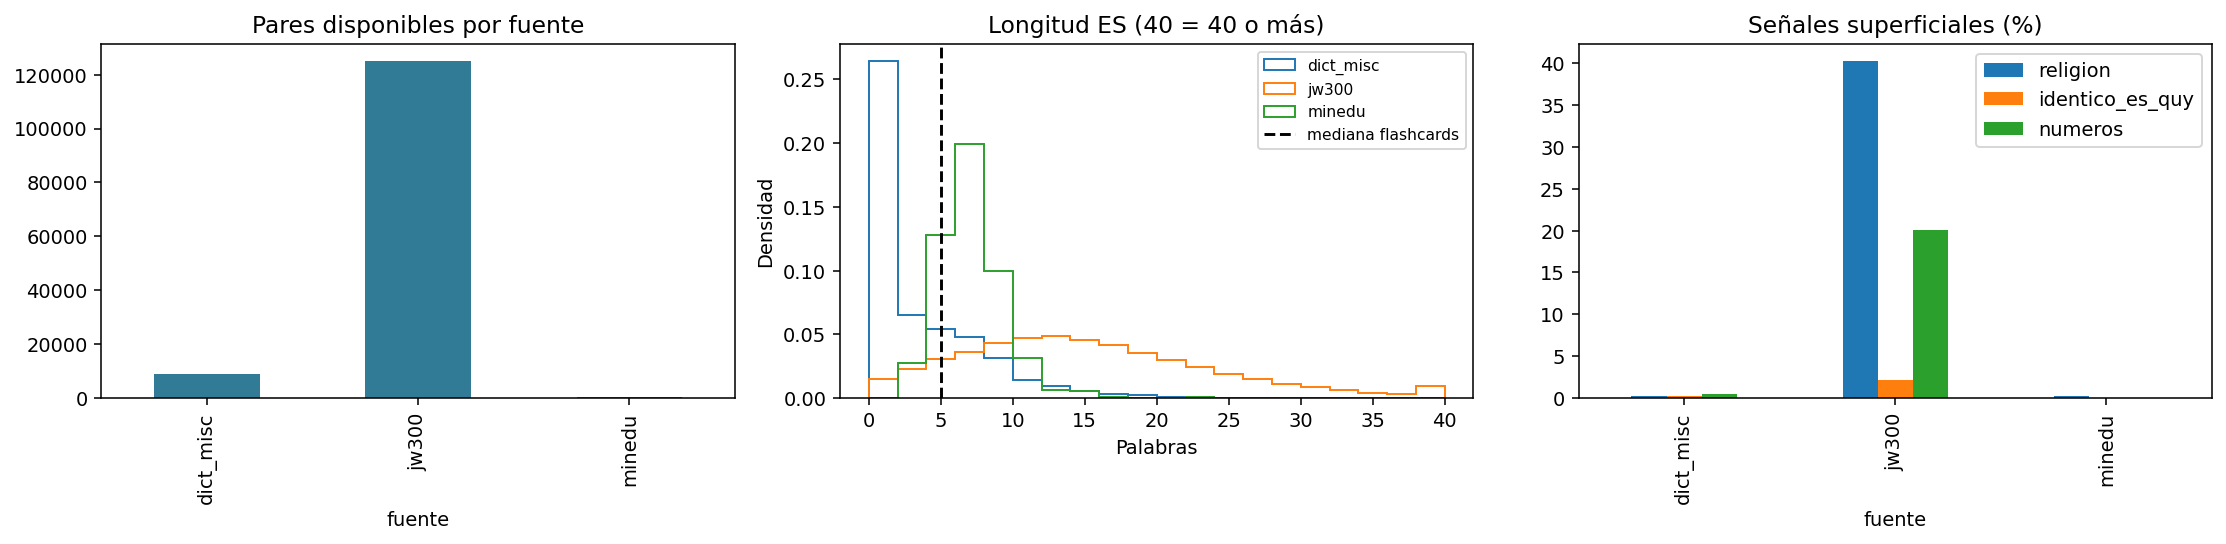

In [4]:
RELIGION = set('dios jehová jesús cristo cristiano cristiana cristianos cristianas biblia bíblico bíblica bíblicos bíblicas iglesia iglesias congregación congregaciones apóstol apóstoles satanás salmo salmos evangelio evangelios espíritu santo sagrada sagrado discípulos predicar predicación reino pecados pecado amén'.split())
STOP = set('el la los las un una unos unas de del a al en por para con y e o u que se es son su sus lo le les como este esta estos estas ese esa esos esas'.split())
TEMAS = {
    'familia_personas': set('madre padre mamá papá hijo hija hijos hijas hermano hermana abuela abuelo familia niño niña mujer hombre bebé'.split()),
    'comida_chacra': set('agua pan comida comer come comemos cocina cocinar pescado maíz papa papas chacra campo sembrar semilla fruta leche arroz'.split()),
    'naturaleza_animales': set('sol luna lluvia río tierra árbol flor perro gato gallina vaca oveja animal animales viento montaña'.split()),
    'casa_vida_diaria': set('casa mesa puerta cama ropa dormir duerme trabaja trabajo escuela camino caminar camina vive vivir jugar juega'.split()),
    'salud_cuerpo': set('mano manos pie pies cabeza ojos boca cuerpo salud enfermo enferma dolor duele'.split())}

for lang in ['es', 'quy']:
    pares[f'n_{lang}'] = pares[f'{lang}_original'].map(lambda s: len(tokens(s)))
    pares[f'chars_{lang}'] = pares[f'{lang}_original'].str.len()
pares['ratio_chars'] = pares.chars_quy / pares.chars_es.clip(lower=1)
pares['vacio'] = pares.es_clave.eq('') | pares.quy_clave.eq('')
pares['identico_es_quy'] = pares.es_clave.eq(pares.quy_clave)
pares['encoding_sospechoso'] = (pares.es_original + ' ' + pares.quy_original).str.contains(r'�|Ã|Â|â€', regex=True)
pares['url_markup'] = (pares.es_original + ' ' + pares.quy_original).str.contains(r'https?://|www\.|<[^>]+>', regex=True)
pares['numeros'] = (pares.es_original + ' ' + pares.quy_original).str.contains(r'\d', regex=True)
pares['ratio_extremo'] = ~pares.ratio_chars.between(.25, 4)
pares['religion'] = pares.es_original.map(lambda s: bool(set(tokens(s)) & RELIGION))
pares['varias_oraciones'] = pares.es_original.str.contains(r'[.!?]\s+[A-ZÁÉÍÓÚÑ¿¡]', regex=True)
pares['duplicado_par'] = pares.duplicated(['es_clave','quy_clave'], keep=False)
pares['n_traducciones_es'] = pares.groupby('es_clave').quy_clave.transform('nunique')
pares['n_es_por_quy'] = pares.groupby('quy_clave').es_clave.transform('nunique')
pares['tipo_longitud'] = pd.cut(pares.n_es, bins=[-1,0,2,7,12,30,np.inf],
    labels=['sin palabras','1–2: léxico / fragmento','3–7: breve','8–12: media','13–30: larga','31+: muy larga'])

def tema(texto):
    ts = set(tokens(texto))
    encontrados = [t for t, vocab in TEMAS.items() if ts & vocab]
    return '|'.join(encontrados) or 'sin_etiqueta'
pares['temas'] = pares.es_original.map(tema)
ALERTAS = ['vacio','identico_es_quy','encoding_sospechoso','url_markup','numeros','ratio_extremo','religion','varias_oraciones','duplicado_par']
resumen_fuentes = pares.groupby('fuente').agg(pares=('par_id','size'), es_unicos=('es_clave','nunique'),
    quy_unicos=('quy_clave','nunique'), mediana_es=('n_es','median'), mediana_quy=('n_quy','median'))
display(resumen_fuentes)
display((pares.groupby('fuente')[ALERTAS].mean()*100).round(2).add_suffix('_pct'))
display(pd.crosstab(pares.fuente, pares.tipo_longitud))
guardar_csv(resumen_fuentes.reset_index(), 'resumen_fuentes.csv')
guardar_csv(pares.groupby('fuente')[ALERTAS].sum().reset_index(), 'conteo_alertas.csv')
guardar_csv(pd.crosstab(pares.fuente, pares.tipo_longitud).reset_index(), 'tipos_longitud.csv')

fig, axes = plt.subplots(1, 3, figsize=(16,4))
resumen_fuentes.pares.plot.bar(ax=axes[0], color='#327b96', title='Pares disponibles por fuente')
for fuente, grupo in pares.groupby('fuente'):
    axes[1].hist(grupo.n_es.clip(upper=40), bins=np.arange(0,42,2), density=True, histtype='step', label=fuente)
axes[1].axvline(principal.n_palabras.median(), color='black', linestyle='--', label='mediana flashcards')
axes[1].set(title='Longitud ES (40 = 40 o más)', xlabel='Palabras', ylabel='Densidad')
axes[1].legend(fontsize=8)
pares.groupby('fuente')[['religion','identico_es_quy','numeros']].mean().mul(100).plot.bar(ax=axes[2], title='Señales superficiales (%)')
mostrar_figura(fig, '01_perfil_corpus.png')


## 4. Recuperación exacta y ambigüedad

Se busca en **todos** los pares, incluso en vocabulario corto y ejemplos que después se descarten
del piloto. `literal_identica` distingue la igualdad literal de la igualdad normalizada.
Una coincidencia normalizada puede diferir en puntuación: debe revisarse, especialmente si cambia
una pregunta por una afirmación. Se exportan todas las alternativas de traducción y procedencia.


In [5]:
columnas_par = ['par_id','fuente','linea','archivo_es','archivo_quy','es_original','quy_original','es_clave','n_traducciones_es']
exactas = referencias[referencias.es_clave.ne('')].merge(pares[columnas_par], on='es_clave', how='inner')
exactas['literal_identica'] = exactas.es_referencia.eq(exactas.es_original)
claves_exactas = set(exactas.es_clave)
referencias['recuperable_exacta_normalizada'] = referencias.es_clave.isin(claves_exactas)
display(referencias.groupby('grupo').agg(referencias=('ref_id','size'),
    recuperables=('recuperable_exacta_normalizada','sum')))
print('Textos ES únicos recuperables:', len(claves_exactas), '/', len(ref_unicas))
display(exactas[['es_referencia','es_original','quy_original','fuente','linea','literal_identica']].head(20))
guardar_csv(exactas, 'coincidencias_exactas_todas.csv')
guardar_csv(referencias[~referencias.recuperable_exacta_normalizada], 'flashcards_sin_par_exacto.csv')

ambiguedades = pares[pares.n_traducciones_es.gt(1) | pares.n_es_por_quy.gt(1)]
guardar_csv(ambiguedades[columnas_par + ['n_es_por_quy']], 'alternativas_traduccion.csv')
cruces = pares.groupby(['es_clave','quy_clave']).fuente.nunique()
print('Pares normalizados presentes en más de una fuente:', int(cruces.gt(1).sum()))


Textos ES únicos recuperables: 126 / 8152
Pares normalizados presentes en más de una fuente: 350


,referencias,recuperables
grupo,,
adicional,7789,124
auxiliar_es,385,1
auxiliar_saludos,44,10
principal,669,3


,es_referencia,es_original,quy_original,fuente,linea,literal_identica
0,Tengo hambre.,tengo hambre.,yarqanayawachkanmi.,dict_misc,2408,False
1,Tengo hambre.,tengo hambre.,yarqawanmi.,dict_misc,2409,False
2,¿Cuántos años tienes?,¿Cuántos años tienes?,¿Hayka watayuqtaq kanki?,dict_misc,2569,True
3,¿Cuántos años tienes?,¿Cuántos años tienes?.,¿Hayka watayuqtaq kanki? .,dict_misc,4105,False
4,¿Cuántos años tienes?,¿Cuántos años tienes?,¿Hayk’a watayuqmi kanki?,dict_misc,6721,False
5,El niño está enfermo.,El niño está enfermo.,Warmachaqa unquchkanmi.,dict_misc,8895,True
6,El niño está enfermo.,El niño está enfermo.,Warmachaqa unquchkanmi.,minedu,533,True
7,Vaya.,¡vaya!,Way way!,dict_misc,2120,False
8,Hola.,Hola.,Ayiyanchu.,dict_misc,445,True
9,Hola.,Hola.,Allillachu.,dict_misc,4682,True


## 5. Candidatos de prosa breve y sensibilidad de los filtros

Se propone inicialmente un rango de 3–12 palabras en español. No prueba que haya una oración
completa: títulos y fragmentos pueden pasar. Se separa el léxico de 1–2 palabras para un posible
ejercicio de vocabulario. No se cortan oraciones largas ni se simplifica su español, porque eso
rompería la relación con la traducción original.

Los filtros numéricos son configurables. No se eliminan datos de la tabla maestra: cada par conserva
los motivos de exclusión del piloto. Se comparan umbrales para no presentar una selección arbitraria
como la única posible. La puntuación y los filtros son hipótesis para validar en una muestra humana.


In [6]:
pares['longitud_es_fuera'] = ~pares.n_es.between(MIN_PALABRAS, MAX_PALABRAS)
pares['longitud_quy_fuera'] = ~pares.n_quy.between(1, MAX_PALABRAS_QUY)
REGLAS = ['vacio','identico_es_quy','encoding_sospechoso','url_markup','numeros','ratio_extremo',
          'religion','varias_oraciones','longitud_es_fuera','longitud_quy_fuera']
pares['motivos_exclusion'] = pares[REGLAS].apply(lambda row: '|'.join(row.index[row]), axis=1)
pares['candidato_superficial'] = pares.motivos_exclusion.eq('')
flujo, mascara = [], pd.Series(True, index=pares.index)
for regla in REGLAS:
    antes = int(mascara.sum())
    mascara &= ~pares[regla]
    flujo.append({'regla_acumulada': regla, 'excluidos_en_paso': antes-int(mascara.sum()), 'restantes': int(mascara.sum())})
display(pd.DataFrame(flujo))
guardar_csv(pd.DataFrame(flujo), 'embudo_filtros.csv')
sensibilidad = []
base_ok = ~pares[[r for r in REGLAS if r != 'longitud_es_fuera']].any(axis=1)
for minimo, maximo in [(2,7),(3,7),(3,12),(3,20)]:
    for fuente in ARCHIVOS:
        sensibilidad.append({'min_es': minimo, 'max_es': maximo, 'fuente': fuente,
            'pares': int((base_ok & pares.n_es.between(minimo,maximo) & pares.fuente.eq(fuente)).sum())})
display(pd.DataFrame(sensibilidad).pivot(index=['min_es','max_es'], columns='fuente', values='pares'))
guardar_csv(pd.DataFrame(sensibilidad), 'sensibilidad_longitud.csv')
lexico = pares[pares.n_es.between(1,2) & ~pares[['vacio','encoding_sospechoso','url_markup','identico_es_quy']].any(axis=1)]
guardar_csv(lexico[columnas_par], 'lexico_corto_para_revision.csv')

# Si un par se repite, se prioriza MINEDU, luego diccionario, luego JW300. Todas las fuentes siguen en pares.
pares['prioridad_fuente'] = pares.fuente.map({'minedu':0,'dict_misc':1,'jw300':2})
pool = pares[pares.candidato_superficial].sort_values(['prioridad_fuente','linea']).drop_duplicates(['es_clave','quy_clave']).copy().reset_index(drop=True)
assert len(pool), 'No quedan candidatos: revisar los parámetros.'
display(pool.groupby('fuente').size().rename('pares_unicos_candidatos'))


,regla_acumulada,excluidos_en_paso,restantes
0,vacio,4409,130242
1,identico_es_quy,2266,127976
2,encoding_sospechoso,0,127976
3,url_markup,112,127864
4,numeros,22326,105538
5,ratio_extremo,183,105355
6,religion,40092,65263
7,varias_oraciones,1440,63823
8,longitud_es_fuera,33207,30616
9,longitud_quy_fuera,0,30616


fuente         dict_misc  jw300  minedu
min_es max_es                          
2      7            2972  12841     457
3      7            2359  11705     452
       12           3243  26748     625
       20           3504  44088     635

fuente
dict_misc     2883
jw300        25531
minedu         625
Name: pares_unicos_candidatos, dtype: int64

## 6. Similitud léxica explicable: TF–IDF de palabras y bigramas

Se indexa solo el español. Los pesos IDF se ajustan sobre los españoles candidatos únicos y las
referencias únicas. Los bigramas conservan algo del orden; se retiran artículos y conectores
frecuentes, pero se conservan negaciones. No hay lematización ni embeddings: sinónimos y flexiones
pueden quedar sin recuperar. El coseno está entre 0 y 1 y **no es una probabilidad**.

Se devuelve hasta tres candidatos por referencia, con umbral exploratorio. Para ordenar nuevas
frases también se obtiene su referencia más cercana. Las coincidencias exactas se calcularon
aparte y no dependen de este umbral. El cálculo por bloques evita una matriz densa completa.


In [7]:
def rasgos(texto):
    ts = tokens(texto)
    palabras = [t for t in ts if t not in STOP]
    bigramas = [a+' '+b for a,b in zip(ts,ts[1:]) if a not in STOP or b not in STOP]
    return palabras + bigramas

documentos = pd.concat([pool.es_clave, ref_unicas.es_clave]).drop_duplicates().tolist()
dfreq = Counter()
for texto in documentos:
    dfreq.update(set(rasgos(texto)))
vocabulario = {t:i for i,t in enumerate(sorted(dfreq))}
idf = np.array([np.log((1+len(documentos))/(1+dfreq[t]))+1 for t in vocabulario], dtype=np.float32)

def matriz_tfidf(textos):
    rows, cols, vals = [], [], []
    for i, texto in enumerate(textos):
        for t, n in Counter(rasgos(texto)).items():
            j = vocabulario.get(t)
            if j is not None:
                rows.append(i); cols.append(j); vals.append((1+np.log(n))*idf[j])
    mat = csr_matrix((np.asarray(vals,dtype=np.float32),(rows,cols)), shape=(len(textos),len(vocabulario)))
    norma = np.sqrt(np.asarray(mat.multiply(mat).sum(axis=1)).ravel())
    return mat.multiply((1/np.maximum(norma,1e-12))[:,None]).tocsr()

X = matriz_tfidf(pool.es_original.tolist())
R = matriz_tfidf(ref_unicas.es_referencia.tolist())
mejor_score = np.zeros(len(pool), dtype=np.float32)
mejor_ref = np.full(len(pool), -1, dtype=int)
vecinos = []
for inicio in range(0, len(ref_unicas), 128):
    similitudes = (R[inicio:inicio+128] @ X.T).toarray()
    idx = similitudes.argmax(axis=0)
    val = similitudes[idx, np.arange(len(pool))]
    mejora = val > mejor_score
    mejor_score[mejora] = val[mejora]
    mejor_ref[mejora] = inicio + idx[mejora]
    for local, fila in enumerate(similitudes):
        ids = np.flatnonzero(fila >= SIM_MIN)
        ids = ids[np.argsort(-fila[ids], kind='stable')[:TOP_K]]
        for rango, j in enumerate(ids,1):
            vecinos.append({'ref_id': ref_unicas.iloc[inicio+local].ref_id,
                'es_referencia': ref_unicas.iloc[inicio+local].es_referencia,
                'es_clave_ref': ref_unicas.iloc[inicio+local].es_clave,
                'par_id': pool.iloc[j].par_id, 'rango': rango, 'coseno_tfidf': float(fila[j])})
    if inicio % 2048 == 0:
        print(f'Referencias procesadas: {min(inicio+128,len(ref_unicas))}/{len(ref_unicas)}')
pool['similitud_referencia'] = mejor_score
pool['ref_id_cercana'] = [ref_unicas.iloc[i].ref_id if i >= 0 else '' for i in mejor_ref]
pool['es_referencia_cercana'] = [ref_unicas.iloc[i].es_referencia if i >= 0 else '' for i in mejor_ref]
recuperacion = pd.DataFrame(vecinos, columns=['ref_id','es_referencia','es_clave_ref','par_id','rango','coseno_tfidf']).merge(pool[columnas_par], on='par_id', how='left')
recuperacion['tipo_match'] = np.where(recuperacion.es_clave_ref.eq(recuperacion.es_clave), 'exacta_normalizada', 'similar_lexica_NO_equivalente')
guardar_csv(recuperacion, 'recuperacion_top3.csv')
display(recuperacion[['es_referencia','es_original','quy_original','coseno_tfidf','tipo_match']].head(20))

cobertura = referencias[['ref_id','grupo','es_referencia','es_clave','recuperable_exacta_normalizada']].copy()
mejores_por_clave = recuperacion.groupby('es_clave_ref').coseno_tfidf.max()
cobertura['mejor_similitud_candidatos'] = cobertura.es_clave.map(mejores_por_clave).fillna(0)
display(cobertura.groupby('grupo').agg(exactas=('recuperable_exacta_normalizada','sum'),
    con_candidato_similar=('mejor_similitud_candidatos', lambda s: s.ge(SIM_MIN).sum())))
guardar_csv(cobertura, 'cobertura_por_flashcard.csv')


Referencias procesadas: 128/8152
Referencias procesadas: 2176/8152
Referencias procesadas: 4224/8152
Referencias procesadas: 6272/8152


,es_referencia,es_original,quy_original,coseno_tfidf,tipo_match
0,El niño va corriendo a la chacra.,En la chacra.,Chacrapim.,0.448152,similar_lexica_NO_equivalente
1,El niño va corriendo a la chacra.,Voy a la chacra.,Chakrata richkani.,0.336324,similar_lexica_NO_equivalente
2,El niño va corriendo a la chacra.,camino a la chacra.,chakraman purini.,0.309098,similar_lexica_NO_equivalente
3,El niño está corriendo en la chacra.,El niño está enfermo.,Warmachaqa unquchkanmi.,0.459383,similar_lexica_NO_equivalente
4,El niño está corriendo en la chacra.,En la chacra.,Chacrapim.,0.452879,similar_lexica_NO_equivalente
5,El niño está corriendo en la chacra.,Voy a la chacra.,Chakrata richkani.,0.339872,similar_lexica_NO_equivalente
6,La mujer canta una canción.,¡Y la mujer se curó!,"Hinaptinmi, ¡chay warmiqa chaylla sanoyarurqa!",0.226925,similar_lexica_NO_equivalente
7,La mujer canta una canción.,¿Puede describir a la mujer?,¿Chiqanchawaqchu warmitaqa?,0.217208,similar_lexica_NO_equivalente
8,La mujer canta una canción.,La mujer está afuera.,Warmiqa hawapim kachkan.,0.217107,similar_lexica_NO_equivalente
9,El perro duerme bajo la mesa.,El perro macho duerme.,Urqu allquqa puñuchkan.,0.343964,similar_lexica_NO_equivalente


,exactas,con_candidato_similar
grupo,,
adicional,124,4588
auxiliar_es,1,320
auxiliar_saludos,10,31
principal,3,564


## 7. Prioridad de revisión, cobertura y piloto diverso

Puntaje exploratorio: 45% cercanía léxica a alguna referencia, 25% parecido de longitud con
la referencia principal, 20% proporción de vocabulario de contenido presente en ella y 10% presencia
de temas cotidianos. Es una preferencia de selección, **no calidad de traducción**. Los componentes
quedan visibles. Las etiquetas de temas son heurísticas y pueden solaparse.

El piloto usa cupos por fuente para evitar que JW300 domine solo por volumen, un máximo de 15
ejemplos por palabra de contenido más infrecuente y un solo ejemplo por español normalizado.
Los cupos que no se cubren no se rellenan automáticamente con otra fuente. La diversidad de palabras
es un proxy limitado: no garantiza balance fonético ni cobertura de sufijos quechuas.


Piloto: 300 / 300 solicitados; cupos máximos: {'minedu': 120, 'dict_misc': 90, 'jw300': 90}
Cobertura de tipos de contenido de la referencia principal:


fuente
dict_misc     90
jw300         90
minedu       120
Name: seleccionados, dtype: int64

,es_original,quy_original,fuente,puntaje_revision,es_referencia_cercana
1964,Ya me voy a dormir.,Puñukamusaqña.,dict_misc,0.940972,Me voy a dormir
514,El niño está enfermo.,Warmachaqa unquchkanmi.,minedu,0.901633,El niño está enfermo.
605,¡Cierra la puerta!,¡Punkuta wichqay!,minedu,0.841970,Cierra la puerta.
1066,El es buen hombre.,Pay sumaq runa.,dict_misc,0.778024,Es un buen hombre.
819,No puedo dormir.,Manan puñuyta atinichu.,dict_misc,0.775303,No puedo dormir.
17029,Ya no sé qué hacer.,Manam ima ruraytapas atinichu.,jw300,0.765331,No sé qué hacer.
5138,Mi padre ahora está mejor.,Papayqa allinñam kachkan.,jw300,0.761493,¿Está mejor?
19306,¿Escucha atentamente a sus hijos?,¿Allintachu warmaykita uyarinki?,jw300,0.759018,Escucha atentamente.
20,Sube al segundo piso.,Altusman siqay.,minedu,0.751601,él sube al segundo piso.
1888,Va al río por agua.,Yakuman richkan mayuta.,dict_misc,0.750334,Vamos al río por la tarde.


en_candidatos    81.237911
en_piloto        33.075435
Name: porcentaje, dtype: float64

,palabra,frecuencia_principal,en_candidatos,en_piloto
48,bailan,9,False,False
51,bajan,9,False,False
56,olvidan,9,False,False
63,viajan,8,False,False
69,cierran,7,False,False
73,lavan,7,False,False
84,pinta,6,False,False
90,nadamos,6,False,False
99,bosque,5,False,False
104,construye,5,False,False


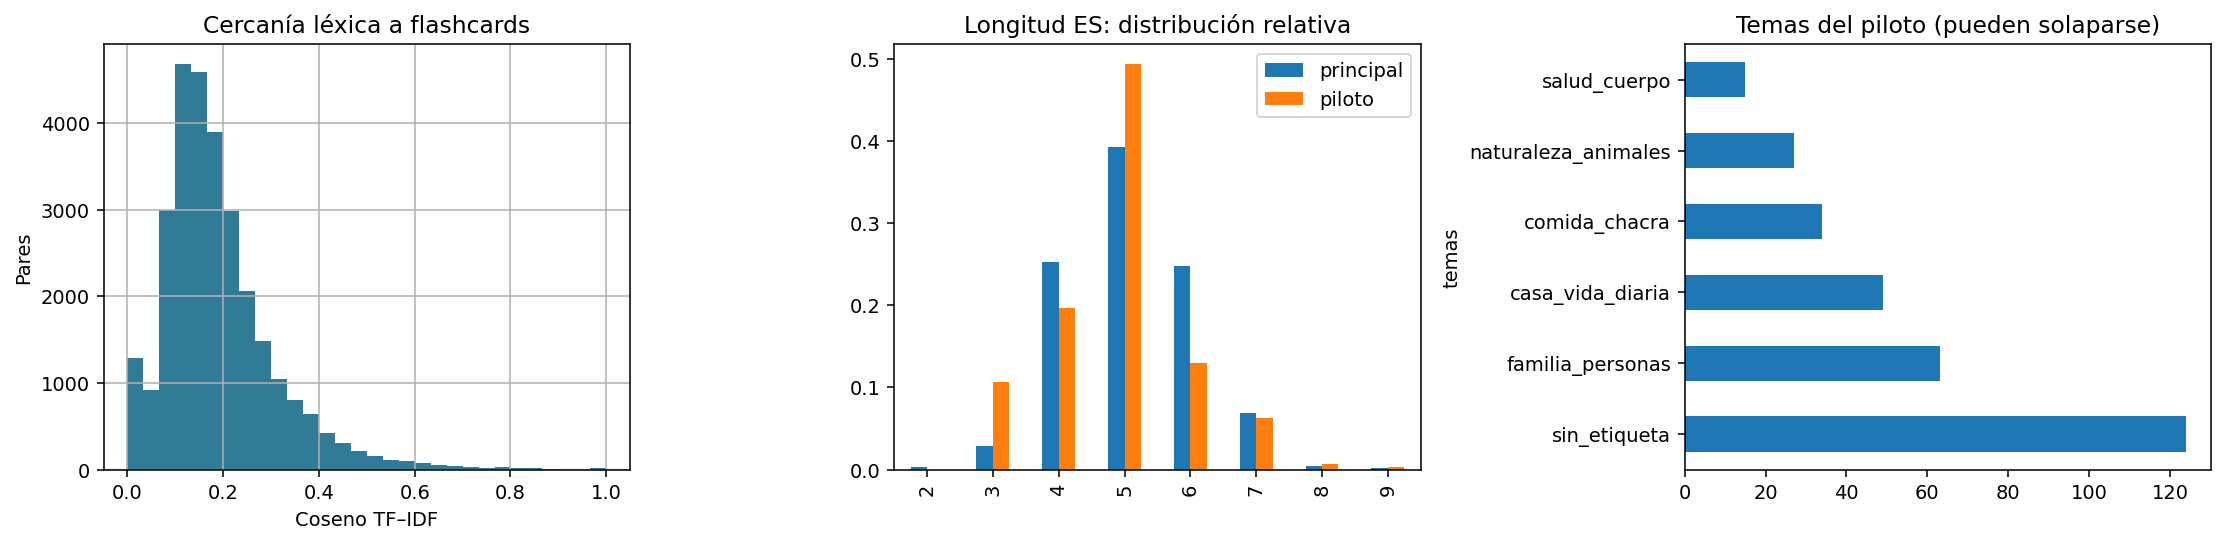

In [8]:
vocab_ref = set(t for s in principal.es_referencia for t in tokens(s) if t not in STOP)
mediana = principal.n_palabras.median()
escala = max(float(principal.n_palabras.quantile(.9)-principal.n_palabras.quantile(.1)), 2.0)
pool['parecido_longitud'] = np.exp(-abs(pool.n_es-mediana)/escala)
pool['cobertura_vocab_principal'] = pool.es_original.map(lambda s:
    len((set(tokens(s))-STOP) & vocab_ref) / max(len(set(tokens(s))-STOP),1))
pool['tema_cotidiano'] = pool.temas.ne('sin_etiqueta').astype(float)
pool['puntaje_revision'] = (.45*pool.similitud_referencia + .25*pool.parecido_longitud
    + .20*pool.cobertura_vocab_principal + .10*pool.tema_cotidiano)
pool['palabra_ancla'] = pool.es_original.map(lambda s:
    min(set(tokens(s))-STOP, key=lambda t:(dfreq.get(t,0),t)) if set(tokens(s))-STOP else '__sin_contenido__')
ranking = pool.sort_values(['puntaje_revision','prioridad_fuente','par_id'], ascending=[False,True,True]).copy()
elegidos, usados, por_fuente, por_ancla = [], set(), Counter(), Counter()
for i, row in ranking.iterrows():
    if len(elegidos) >= N_PILOTO:
        break
    if por_fuente[row.fuente] >= CUOTAS[row.fuente] or row.es_clave in usados or por_ancla[row.palabra_ancla] >= 15:
        continue
    elegidos.append(i); usados.add(row.es_clave)
    por_fuente[row.fuente] += 1; por_ancla[row.palabra_ancla] += 1
piloto = ranking.loc[elegidos].copy()
print(f'Piloto: {len(piloto)} / {N_PILOTO} solicitados; cupos máximos: {CUOTAS}')
display(piloto.groupby('fuente').size().rename('seleccionados'))
display(piloto[['es_original','quy_original','fuente','puntaje_revision','es_referencia_cercana']].head(25))

vocab_candidatos = set(t for s in pool.es_original for t in tokens(s) if t not in STOP)
vocab_piloto = set(t for s in piloto.es_original for t in tokens(s) if t not in STOP)
freq_ref = Counter(t for s in principal.es_referencia for t in tokens(s) if t not in STOP)
tabla_vocab = pd.DataFrame([{'palabra': t, 'frecuencia_principal': n,
    'en_candidatos': t in vocab_candidatos, 'en_piloto': t in vocab_piloto} for t,n in freq_ref.most_common()])
guardar_csv(tabla_vocab, 'cobertura_vocabulario.csv')
print('Cobertura de tipos de contenido de la referencia principal:')
display(tabla_vocab[['en_candidatos','en_piloto']].mean().mul(100).rename('porcentaje'))
display(tabla_vocab[~tabla_vocab.en_candidatos].head(25))

fig, axes = plt.subplots(1,3,figsize=(16,4))
pool.similitud_referencia.hist(bins=30,ax=axes[0],color='#327b96')
axes[0].set(title='Cercanía léxica a flashcards',xlabel='Coseno TF–IDF',ylabel='Pares')
pd.DataFrame({'principal': principal.n_palabras.value_counts(normalize=True),
    'piloto': piloto.n_es.value_counts(normalize=True)}).sort_index().plot.bar(ax=axes[1],title='Longitud ES: distribución relativa')
piloto.temas.str.split('|').explode().value_counts().plot.barh(ax=axes[2],title='Temas del piloto (pueden solaparse)')
mostrar_figura(fig, '02_seleccion_piloto.png')


## 8. Muestra de auditoría y hoja para revisión con hablantes

Se auditan también descartados: revisar solo los mejores oculta falsos negativos. Se extraen hasta
20 pares por fuente y condición (candidato/descartado), con semilla fija. La muestra mide comportamiento
de reglas; no representa por sí sola la distribución del corpus. Para estimar precisión del ranking,
conviene etiquetar además muestras por intervalos de puntaje y ajustar los filtros después.

En el piloto, revisar: (1) si es una oración autónoma y natural, (2) correspondencia ES–QUY,
(3) variedad Chanka y ortografía acordada con la comunidad, (4) adecuación para lectura en voz alta.
Registrar correcciones en columnas nuevas, conservando los originales. **Todas las filas empiezan
pendientes; ninguna está aprobada automáticamente para grabar.** `AUDIO?` / `Grabado?` de los Excel
no se copian. Identificadores de hablante deben ser seudónimos.


In [9]:
auditoria = pd.concat([g.sample(n=min(20,len(g)),random_state=SEED)
    for _,g in pares.groupby(['fuente','candidato_superficial'])],ignore_index=True)
for col in ['alineacion_humana','variedad_chanka_humana','oracion_autonoma_humana','decision_humana','observaciones']:
    auditoria[col] = ''
guardar_csv(auditoria, 'muestra_auditoria.csv')

columnas_revision = ['par_id','fuente','archivo_es','archivo_quy','linea','es_original','quy_original',
    'n_es','n_quy','temas','n_traducciones_es','n_es_por_quy','puntaje_revision','similitud_referencia',
    'parecido_longitud','cobertura_vocab_principal','tema_cotidiano','ref_id_cercana','es_referencia_cercana']
revision = piloto[columnas_revision].copy()
revision.insert(0,'orden_revision',np.arange(1,len(revision)+1))
revision['estado'] = 'pendiente_revision'
for col in ['alineacion_validada','chanka_validado','naturalidad_validada','texto_es_aprobado','texto_quy_aprobado',
    'revisor_id','observaciones','hablante_id','sesion_id','archivo_audio','duracion_segundos','control_audio']:
    revision[col] = ''
revision.to_csv(RUN / 'piloto_revision.csv',index=False,encoding='utf-8-sig')
instrucciones = pd.DataFrame([
    ['estado','pendiente_revision / corregir / rechazado / aprobado_para_grabar / grabado'],
    ['alineacion_validada','sí / no / dudoso; ¿ambos textos expresan lo mismo?'],
    ['chanka_validado','sí / no / dudoso; validación por hablante competente'],
    ['naturalidad_validada','sí / no / dudoso; oración autónoma y fácil de leer'],
    ['texto_es_aprobado / texto_quy_aprobado','Completar ambos después de revisión; conservar originales'],
    ['aprobado_para_grabar','Solo tras validar alineación, variedad y naturalidad'],
    ['es_referencia_cercana','Solo referencia de similitud: no sustituir el español original por ella'],
    ['procedencia','Validar atribución y condiciones de cada fuente antes de distribuir el corpus'],
    ['audio','Acordar consentimiento, uso y atribución con los participantes; usar IDs de hablante'],
    ['particiones','Para ASR, separar por hablante y controlar frases repetidas entre train/dev/test']
],columns=['campo','instruccion'])
with pd.ExcelWriter(RUN / 'piloto_revision.xlsx',engine='openpyxl') as writer:
    revision.to_excel(writer,sheet_name='revision',index=False)
    instrucciones.to_excel(writer,sheet_name='instrucciones',index=False)
    ws = writer.book['revision']
    ws.freeze_panes = 'H2'
    ws.auto_filter.ref = ws.dimensions
    from openpyxl.worksheet.datavalidation import DataValidation
    from openpyxl.utils import get_column_letter
    from openpyxl.styles import Alignment
    for j, nombre in enumerate(revision.columns,1):
        ws.column_dimensions[get_column_letter(j)].width = 55 if nombre in ['es_original','quy_original','es_referencia_cercana','texto_es_aprobado','texto_quy_aprobado'] else 23
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = Alignment(wrap_text=True,vertical='top')
            # El Excel de revisión debe mostrar texto, incluso si una fuente empieza por '='.
            if isinstance(cell.value,str) and cell.value.startswith('='):
                cell.data_type = 's'
    val = DataValidation(type='list',formula1='"pendiente_revision,corregir,rechazado,aprobado_para_grabar,grabado"')
    ws.add_data_validation(val)
    letra = get_column_letter(revision.columns.get_loc('estado')+1)
    val.add(f'{letra}2:{letra}{len(revision)+1}')

guardar_csv(ranking, 'candidatos_ordenados.csv')
pares.to_csv(OUT / 'pares_auditados.csv.gz',index=False,encoding='utf-8',compression='gzip')
auditoria.to_csv(RUN / 'muestra_auditoria.csv',index=False,encoding='utf-8-sig')
print('Hoja de trabajo:', RUN / 'piloto_revision.xlsx')


Hoja de trabajo: C:\Users\PC\Desktop\GestionConocimientoTA\DataRecolectada\resultados_eda\revision_20260926T164509_467500Z\piloto_revision.xlsx


## 9. Comprobaciones e interpretación

Los controles siguientes comprueban la trazabilidad, la conservación de los pares y el funcionamiento
del índice; no certifican traducción ni variedad. No se exportan pares nuevos `.es/.quy` aprobados:
primero se completa la revisión humana. Para grabar, se lee el **quechua aprobado** y se mantiene el
español aprobado como significado paralelo.


In [10]:
assert pares.par_id.is_unique
assert len(pares) == sum(x['lineas_es'] for x in conteos)
assert not piloto.duplicated('es_clave').any()
assert piloto.candidato_superficial.all()
assert len(piloto) <= N_PILOTO
assert all(n <= CUOTAS[f] for f,n in piloto.fuente.value_counts().items())
assert not revision.estado.eq('aprobado_para_grabar').any()
assert pool.similitud_referencia.between(0,1.00001).all()
assert tokens('niño mamá ñan') == ['niño','mamá','ñan']
assert clave('¿Cómo estás?') == clave('cómo estás.')
assert clave('sí') != clave('si')
assert clave('No come.') != clave('Come.')
for fuente, base in ARCHIVOS.items():
    es = (DATA_DIR / f'{base}.es').read_text(encoding='utf-8-sig').splitlines()
    qu = (DATA_DIR / f'{base}.quy').read_text(encoding='utf-8-sig').splitlines()
    for row in piloto[piloto.fuente.eq(fuente)].itertuples():
        assert row.es_original == es[row.linea-1]
        assert row.quy_original == qu[row.linea-1]
# Comprueba contra fuerza bruta una pequeña submatriz del resultado por bloques.
for j in range(min(5,len(pool))):
    brute = (R @ X[j].T).toarray().ravel()
    assert np.isclose(brute.max(),pool.iloc[j].similitud_referencia,atol=1e-6)
releido = pd.read_excel(RUN / 'piloto_revision.xlsx',sheet_name='revision')
assert len(releido) == len(revision)
assert releido.quy_original.tolist() == revision.quy_original.tolist()

metricas = {
    'pares_posicionales': len(pares), 'pares_por_fuente': pares.fuente.value_counts().to_dict(),
    'referencias_unicas': len(ref_unicas), 'referencias_unicas_con_exacto': len(claves_exactas),
    'pares_candidatos_unicos': len(pool), 'piloto': len(piloto),
    'piloto_por_fuente': piloto.fuente.value_counts().to_dict(),
    'referencias_principales_con_exacto': int(referencias.loc[referencias.grupo.eq('principal'),'recuperable_exacta_normalizada'].sum()),
    'mediana_palabras_principal': float(mediana),
    'revision_directorio': RUN.name,
    'parametros': {'min_es':MIN_PALABRAS,'max_es':MAX_PALABRAS,'max_quy':MAX_PALABRAS_QUY,
        'top_k':TOP_K,'sim_min':SIM_MIN,'semilla':SEED,'cupos':CUOTAS},
    'entorno': {'python':sys.version,'plataforma':platform.platform(),'pandas':pd.__version__,
        'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__}}
(OUT / 'resumen_ejecucion.json').write_text(json.dumps(metricas,ensure_ascii=False,indent=2),encoding='utf-8')
(RUN / 'resumen_ejecucion.json').write_text(json.dumps(metricas,ensure_ascii=False,indent=2),encoding='utf-8')
inventario.to_csv(RUN / 'inventario.csv',index=False,encoding='utf-8-sig')
print(json.dumps(metricas,ensure_ascii=False,indent=2))
print('Comprobaciones técnicas completadas. Validación lingüística pendiente.')


{
  "pares_posicionales": 134651,
  "pares_por_fuente": {
    "jw300": 125008,
    "dict_misc": 9000,
    "minedu": 643
  },
  "referencias_unicas": 8152,
  "referencias_unicas_con_exacto": 126,
  "pares_candidatos_unicos": 29039,
  "piloto": 300,
  "piloto_por_fuente": {
    "minedu": 120,
    "dict_misc": 90,
    "jw300": 90
  },
  "referencias_principales_con_exacto": 3,
  "mediana_palabras_principal": 5.0,
  "revision_directorio": "revision_20260926T164509_467500Z",
  "parametros": {
    "min_es": 3,
    "max_es": 12,
    "max_quy": 25,
    "top_k": 3,
    "sim_min": 0.2,
    "semilla": 42,
    "cupos": {
      "minedu": 120,
      "dict_misc": 90,
      "jw300": 90
    }
  },
  "entorno": {
    "python": "3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]",
    "plataforma": "Windows-10-10.0.19045-SP0",
    "pandas": "3.0.1",
    "numpy": "1.26.4",
    "scipy": "1.16.0",
    "matplotlib": "3.10.3"
  }
}
Comprobaciones técnicas completadas. Validación 

## 10. Qué hacer después y límites del análisis

1. Revisar el piloto y la muestra de descartados con hablantes de Chanka. Medir cuántos son correctos,
   naturales y autónomos antes de ampliar la selección. Analizar resultados por fuente y puntaje.
2. Ajustar longitud, términos de dominio y cupos según los errores observados. Un coseno alto puede
   compartir palabras y cambiar negación, persona o significado; uno bajo puede ser un buen ejemplo.
3. Completar temas cotidianos ausentes mediante elicitación con hablantes y traducción revisada,
   marcando esa procedencia distinta. No inventar el quechua que falta ni copiar el de una frase similar.
4. Antes de un lote grande, hacer una sesión pequeña de lectura para medir duración real, comodidad,
   pronunciación y calidad de audio. No se estima duración en quechua a partir de palabras españolas.
5. Revisar distribución fonética y morfológica de los textos quechuas ya validados. Este EDA no
   incluye un analizador morfológico, clasificador dialectal ni balance fonético automático.

**Referencias metodológicas y de procedencia** (contexto; no prueban la versión de los archivos locales):

- [Agić y Vulić, 2019, JW300](https://aclanthology.org/P19-1310/): origen y construcción del corpus.
  Su procedencia religiosa justifica estudiar el dominio, aunque contiene otros temas.
- [REPU CS, AmericasNLP 2021](https://aclanthology.org/2021.americasnlp-1.27/): recopilación de
  recursos español–quechua de fuentes heterogéneas.
- [QuBERT, 2022](https://aclanthology.org/2022.deeplo-1.1/): corpus para quechua sureño y sus variedades.
- [Modeling the Sacred, 2024](https://aclanthology.org/2024.findings-naacl.65/): limitaciones
  de datos religiosos y antecedentes sobre permisos de JW300. La existencia de los archivos no
  acredita autorización para redistribuirlos; registrar las condiciones verificadas de cada fuente.

No hay metadatos locales de licencia, versión, hablantes ni alineador. Por eso se preserva la
procedencia física sin atribuir a estos archivos una calidad o licencia no documentada.
